In [1]:
import numpy as np
import pandas as pd
import xarray as xr
import pyremo as pr
import os
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import matplotlib as mpl
import matplotlib.patches as mpatches
from REMO2020TEB_mod import flip, modelclass_cities, open_prepare_dwd_uhi, prepare_remo_to_umask_seas
os.environ['PATH'] = '/work/ch0636/g300096/Python/envs/kernelR2020TEB/bin:' + os.environ['PATH']

/work/ch0636/g300096/Python/envs/kernelR2020TEB/lib/python3.10/site-packages/pyremo/__init__.py:1: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


In [2]:
# create variable info class for measurements
class dwdclass:
    def __init__(self,station,urstation_id,rurstation_names):
        self.station = station
        self.urstation_id = urstation_id
        self.rurstation_names = rurstation_names
        self.data = []
        self.urb_data = []
        self.rur_data = []

In [3]:
# Init dwdclass
dwd_data =[] # init
#
dwd_data.append(dwdclass("Hamburg","15973",['produkt_tu_stunde_19910101_20251231_00704','produkt_tu_stunde_20020124_20251231_01736']))
dwd_data.append(dwdclass("Hannover","15811",['produkt_tu_stunde_20020101_20251231_00368','produkt_tu_stunde_20020101_20251231_00850']))
dwd_data.append(dwdclass("Berlin","399",['produkt_tu_stunde_19560101_20251231_00164','produkt_tu_stunde_19930819_20251231_00303']))

In [4]:
# give figure path
figpath = './figures/'

In [5]:
# Give the quantiles to be calculated (must inlcude 0.5)
quantiles = np.array([0.05,0.25,0.5,0.75,0.95])

In [6]:
# if we want to replace median with mean
lreplace_median=True

In [7]:
# Open dwd datasets
dwd_dpath = '/work/ch0636/g300096/data/TEB_analysis/station_data/'
for stat in dwd_data:
    stat.data, stat.urb_data, stat.rur_data = open_prepare_dwd_uhi(dwd_dpath+f'{stat.station}/','uhi',f'produkt_air_temperature_{stat.urstation_id}_akt','LUFTTEMPERATUR',stat.rurstation_names,'TT_TU',2020,quantiles,lreplace_median,addc=273.15)

In [8]:
# REMO hourly datapath
remo_datap = "/work/ch0636/g300096/results/TEB/post-processed"

In [9]:
# define the runs to be analysed
modelruns =[] # init

# 
modelruns.append(modelclass_cities("036047","REMO2020 TEB","ECOSG_LCZ",'b-','0.0275'))
modelruns.append(modelclass_cities("036048","REMO2020 TEB iMOVE","LANDMATE",'r-','0.0275'))
modelruns.append(modelclass_cities("036049","REMO2020","GLCC",'c-','0.0275'))
modelruns.append(modelclass_cities("036043","REMO2020 TEB","ECOSG_LCZ",'b--','0.11'))
modelruns.append(modelclass_cities("036044","REMO2020 TEB iMOVE","LANDMATE",'r--','0.11'))
modelruns.append(modelclass_cities("036041","REMO2020","GLCC",'c--','0.11'))

In [10]:
## read in remo data and do masking
varname = "TEMP2"
for obj in modelruns:
    # open remo data
    remo_data = pr.parse_dates(xr.open_dataset(remo_datap+"/"+obj.userexp+"_postpro_1h_2020.nc"))
    # create initial xarray datasets
    obj.vardata = xr.Dataset()
    obj.urb_data = xr.Dataset()
    obj.rur_data = xr.Dataset()
    # loop over stations
    for stat in dwd_data:
        # read in mask file (depends on the resolution and station)
        if (obj.reso == '0.0275'):
            urb_rur_remo_mask = xr.open_dataset(f"./data_in/model_data/REMO_static/urmask_{stat.station}-ALPX-3_urclim_masks_fx.nc")
        elif (obj.reso == '0.11'):
            urb_rur_remo_mask = xr.open_dataset(f"./data_in/model_data/REMO_static/urmask_{stat.station}-EUR-11_urclim_masks_fx.nc")
        # merge remo data and the mask
        merged_data = xr.merge([remo_data,urb_rur_remo_mask[obj.maskname]],compat="override", join="override")
        # Shift time by 30 minutes backwards (REMO specific)
        merged_data = merged_data.assign_coords(time=merged_data.time - pd.Timedelta('30min'))
        # filter the data based on the mask
        stat_data_urb_raw = merged_data[varname].where(merged_data[obj.maskname] > 0.5,drop=True)
        stat_data_rur_raw = merged_data[varname].where(merged_data[obj.maskname] < 0.5,drop=True)
        # create weight and make a mean
        weight_urb = np.cos(np.deg2rad(stat_data_urb_raw.rlat))
        weight_rur = np.cos(np.deg2rad(stat_data_rur_raw.rlat))
        stat_data_urb_raw = stat_data_urb_raw.weighted(weight_urb).mean(dim=("rlat", "rlon")).squeeze().compute()
        stat_data_rur_raw = stat_data_rur_raw.weighted(weight_rur).mean(dim=("rlat", "rlon")).squeeze().compute()
        uhi_tmp_raw = (stat_data_urb_raw-stat_data_rur_raw)
        # add coordinates for seasons and hours
        uhi_tmp_raw = uhi_tmp_raw.assign_coords(season=uhi_tmp_raw.time.dt.season,hour=uhi_tmp_raw.time.dt.hour)
        # collect urban/rural data
        urb_data_final = stat_data_urb_raw.assign_coords(season=stat_data_urb_raw.time.dt.season,hour=stat_data_urb_raw.time.dt.hour).groupby(["season", "hour"]).quantile(quantiles, dim='time').squeeze()
        rur_data_final = stat_data_rur_raw.assign_coords(season=stat_data_rur_raw.time.dt.season,hour=stat_data_rur_raw.time.dt.hour).groupby(["season", "hour"]).quantile(quantiles, dim='time').squeeze()
        final_data = uhi_tmp_raw.groupby(["season", "hour"]).quantile(quantiles, dim='time')
        if (lreplace_median):
            final_data.loc[dict(quantile=0.5)] = uhi_tmp_raw.groupby(["season", "hour"]).mean("time") # mask is 1.0
            urb_data_final.loc[dict(quantile=0.5)] = stat_data_urb_raw.assign_coords(season=stat_data_urb_raw.time.dt.season,hour=stat_data_urb_raw.time.dt.hour).groupby(["season", "hour"]).mean("time").squeeze()
            rur_data_final.loc[dict(quantile=0.5)] = stat_data_rur_raw.assign_coords(season=stat_data_rur_raw.time.dt.season,hour=stat_data_rur_raw.time.dt.hour).groupby(["season", "hour"]).mean("time").squeeze()
        #
        obj.vardata = obj.vardata.assign({stat.station:final_data.compute()})
        obj.urb_data = obj.urb_data.assign({stat.station:urb_data_final.compute()})
        obj.rur_data = obj.rur_data.assign({stat.station:rur_data_final.compute()})

In [11]:
# Define the order of seasons to be used (also when plotting)
seasons = ["DJF","MAM","JJA","SON"]

In [12]:
# select plotted quantiles for shading (and 1-q)
ploquan = [0.05,0.25]

In [13]:
# Reset and set rcParams
mpl.rcParams.update(mpl.rcParamsDefault)
#plt.rcParams["figure.figsize"] = (25, 25)
plt.rcParams["figure.subplot.wspace"] = 0.3
plt.rcParams["figure.subplot.hspace"] = 0.1
plt.rcParams["axes.titlesize"] = 26
plt.rcParams['axes.labelsize'] = 22
plt.rcParams["xtick.top"] = True
plt.rcParams["xtick.labeltop"] = False
plt.rcParams["xtick.bottom"] = True
plt.rcParams["xtick.labelbottom"] = True
plt.rcParams["ytick.left"] = True
plt.rcParams["ytick.labelleft"] = True
plt.rcParams["ytick.right"] = True
plt.rcParams["ytick.labelright"] = False
plt.rcParams['lines.markersize'] = 10
plt.rc('text', usetex=True)
plt.rc('font', family='serif')
plt.rc('xtick', labelsize=24) 
plt.rc('ytick', labelsize=24) 
plt.rc('legend', fontsize=22)

# Prepare temperature plots

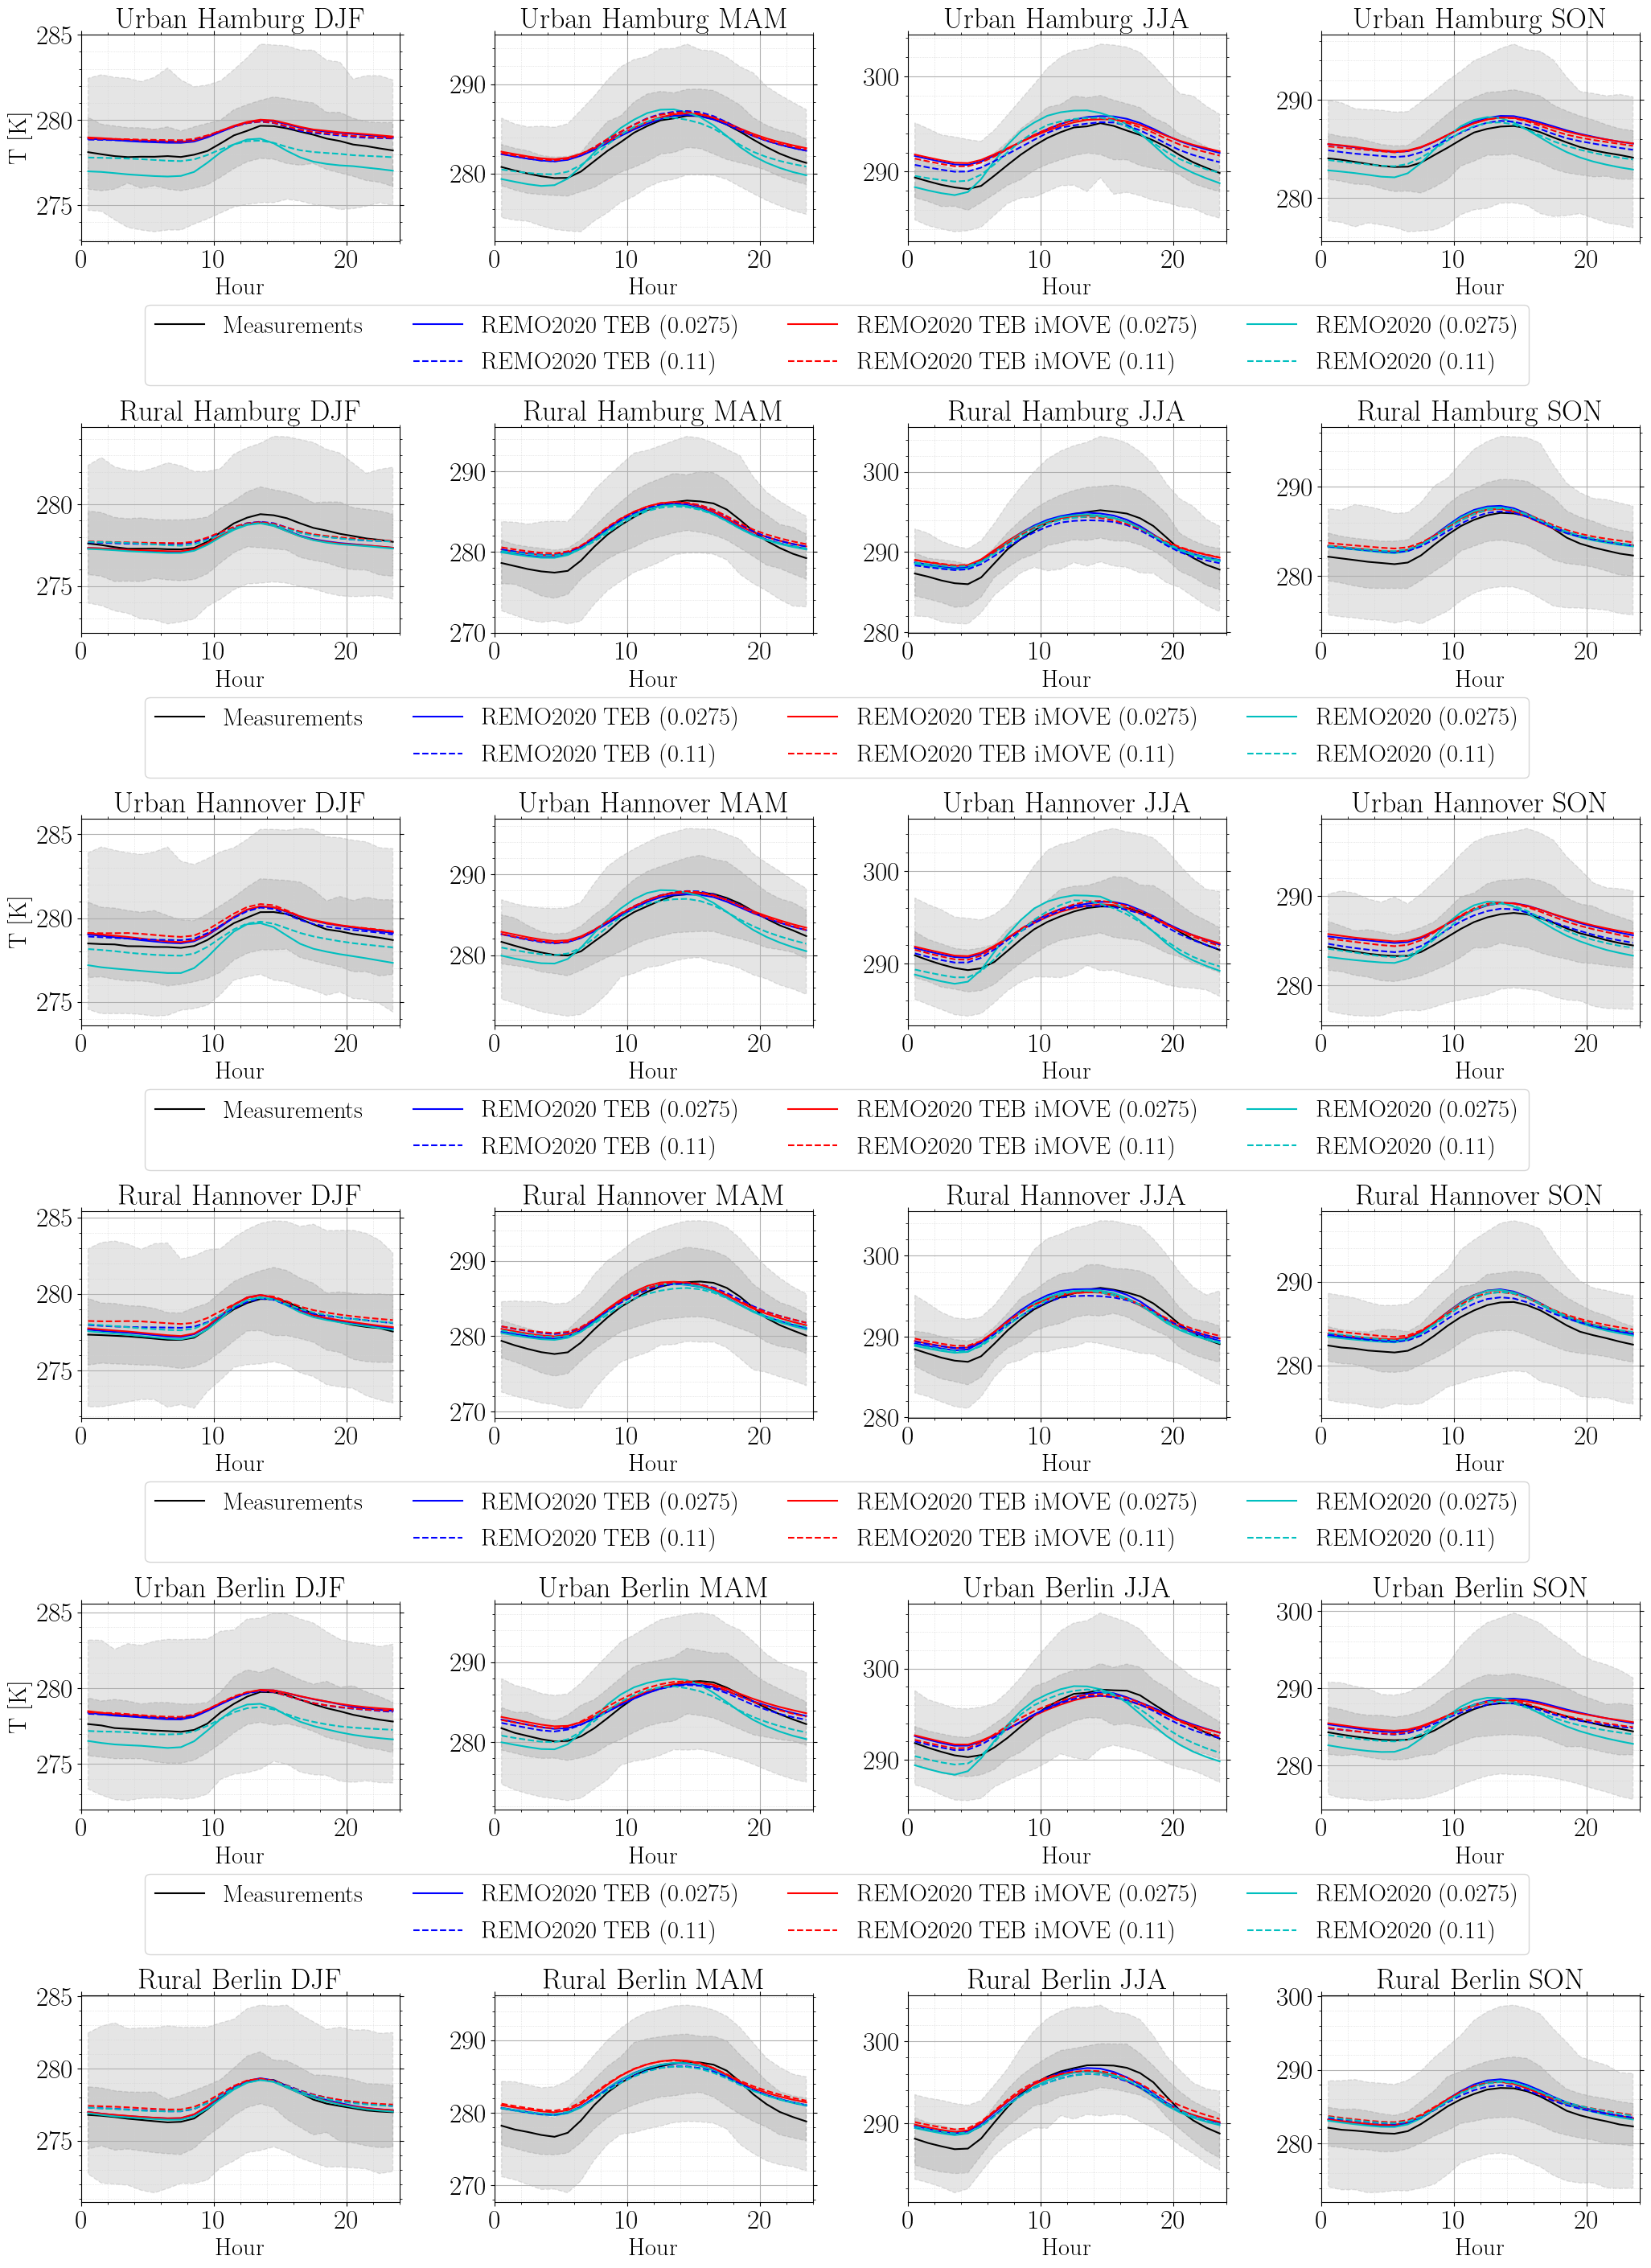

In [23]:
# plot specific configs
plt.rcParams["figure.subplot.hspace"] = 0.9
# Create subplots: station_count rows, 6 columns
fig, ax = plt.subplots(len(dwd_data)*2, 4, figsize=(25, 35))
ax = ax.flatten()  # Flatten for easy indexing

# number of legend columns
ncol = 4
# some helper indexes
ind = 0
for seas in seasons:
    istat = 0
    for stat in dwd_data:
        # urb mes
        ax[ind+istat].grid() # make grid and modify it
        ax[ind+istat].grid(which='minor', color='lightgrey', linestyle=':', linewidth=0.5)
        ax[ind+istat].minorticks_on() # use minor ticks
        # Urban plot (measurements)
        ax[ind+istat].plot(stat.urb_data.hour.values+0.5,
                     stat.urb_data.sel(season=seas).sel(quantile=0.5).values,
                     'k-', label="Measurements")
        for qq in ploquan:
            ax[ind+istat].fill_between(stat.urb_data.hour.values+0.5,
                                stat.urb_data.sel(season=seas).sel(quantile=qq).values, stat.urb_data.sel(season=seas).sel(quantile=1.0-qq).values,
                                color='k', alpha=0.1, linewidth=1, linestyle = '--')
        # rur mes
        ax[ind+istat+len(seasons)].grid() # make grid and modify it
        ax[ind+istat+len(seasons)].grid(which='minor', color='lightgrey', linestyle=':', linewidth=0.5)
        ax[ind+istat+len(seasons)].minorticks_on() # use minor ticks
        # Urban plot (measurements)
        ax[ind+istat+len(seasons)].plot(stat.rur_data.hour.values+0.5,
                     stat.rur_data.sel(season=seas).sel(quantile=0.5).values,
                     'k-', label="Measurements")
        for qq in ploquan:
            ax[ind+istat+len(seasons)].fill_between(stat.rur_data.hour.values+0.5,
                                stat.rur_data.sel(season=seas).sel(quantile=qq).values, stat.rur_data.sel(season=seas).sel(quantile=1.0-qq).values,
                                color='k', alpha=0.1, linewidth=1, linestyle = '--')
        # modelruns
        for obj in modelruns:
            # urban
            ax[ind+istat].plot(obj.urb_data.hour.values+0.5,
                         obj.urb_data[stat.station].sel(season=seas).sel(quantile=0.5).values,
                         obj.plstyle, label=obj.runame+" ("+obj.reso+")")
            # rural
            ax[ind+istat+len(seasons)].plot(obj.rur_data.hour.values+0.5,
                         obj.rur_data[stat.station].sel(season=seas).sel(quantile=0.5).values,
                         obj.plstyle, label=obj.runame+" ("+obj.reso+")")

        ax[ind+istat].set_title(f"Urban {stat.station} {seas}")
        ax[ind+istat+len(seasons)].set_title(f"Rural {stat.station} {seas}")
        ax[ind+istat].set_xlabel("Hour")
        ax[ind+istat+len(seasons)].set_xlabel("Hour")
        ax[ind+istat].set_xlim([0,24])
        ax[ind+istat+len(seasons)].set_xlim([0,24])
        if seas == "DJF":
            ax[ind+istat].set_ylabel("T [K]")
            if(istat != (len(dwd_data)+1)*len(seasons)):
                # flip and insert one empty string
                handles, labels = ax[ind+istat].get_legend_handles_labels()
                empty_patch = mpatches.Patch(color='none', label='') # create a patch with no color
                handles.insert(ncol, empty_patch)
                labels.insert(ncol,'')
                # first legend
                leg1 = ax[ind+istat].legend(flip(handles, ncol), flip(labels, ncol),loc=(0.2, -0.7), ncol=ncol, frameon=True)
                # Add it back to the axes
                ax[ind+istat].add_artist(leg1)
                # second legend
                ax[ind+istat].legend(flip(handles, ncol), flip(labels, ncol),loc=(0.2, -2.6), ncol=ncol, frameon=True)
            else:
                # flip and insert one empty string
                handles, labels = ax[ind+istat].get_legend_handles_labels()
                empty_patch = mpatches.Patch(color='none', label='') # create a patch with no color
                handles.insert(ncol, empty_patch)
                labels.insert(ncol,'')
                ax[ind+istat].legend(flip(handles, ncol), flip(labels, ncol),loc=(0.2, -0.7), ncol=ncol, frameon=True)
        # increas counter
        istat += len(seasons)*2
    # increas counter
    ind += 1

    
plt.savefig(figpath + 'fig15.png', format="png", bbox_inches='tight', pad_inches=0)
plt.show()

### Prepare UHI plots

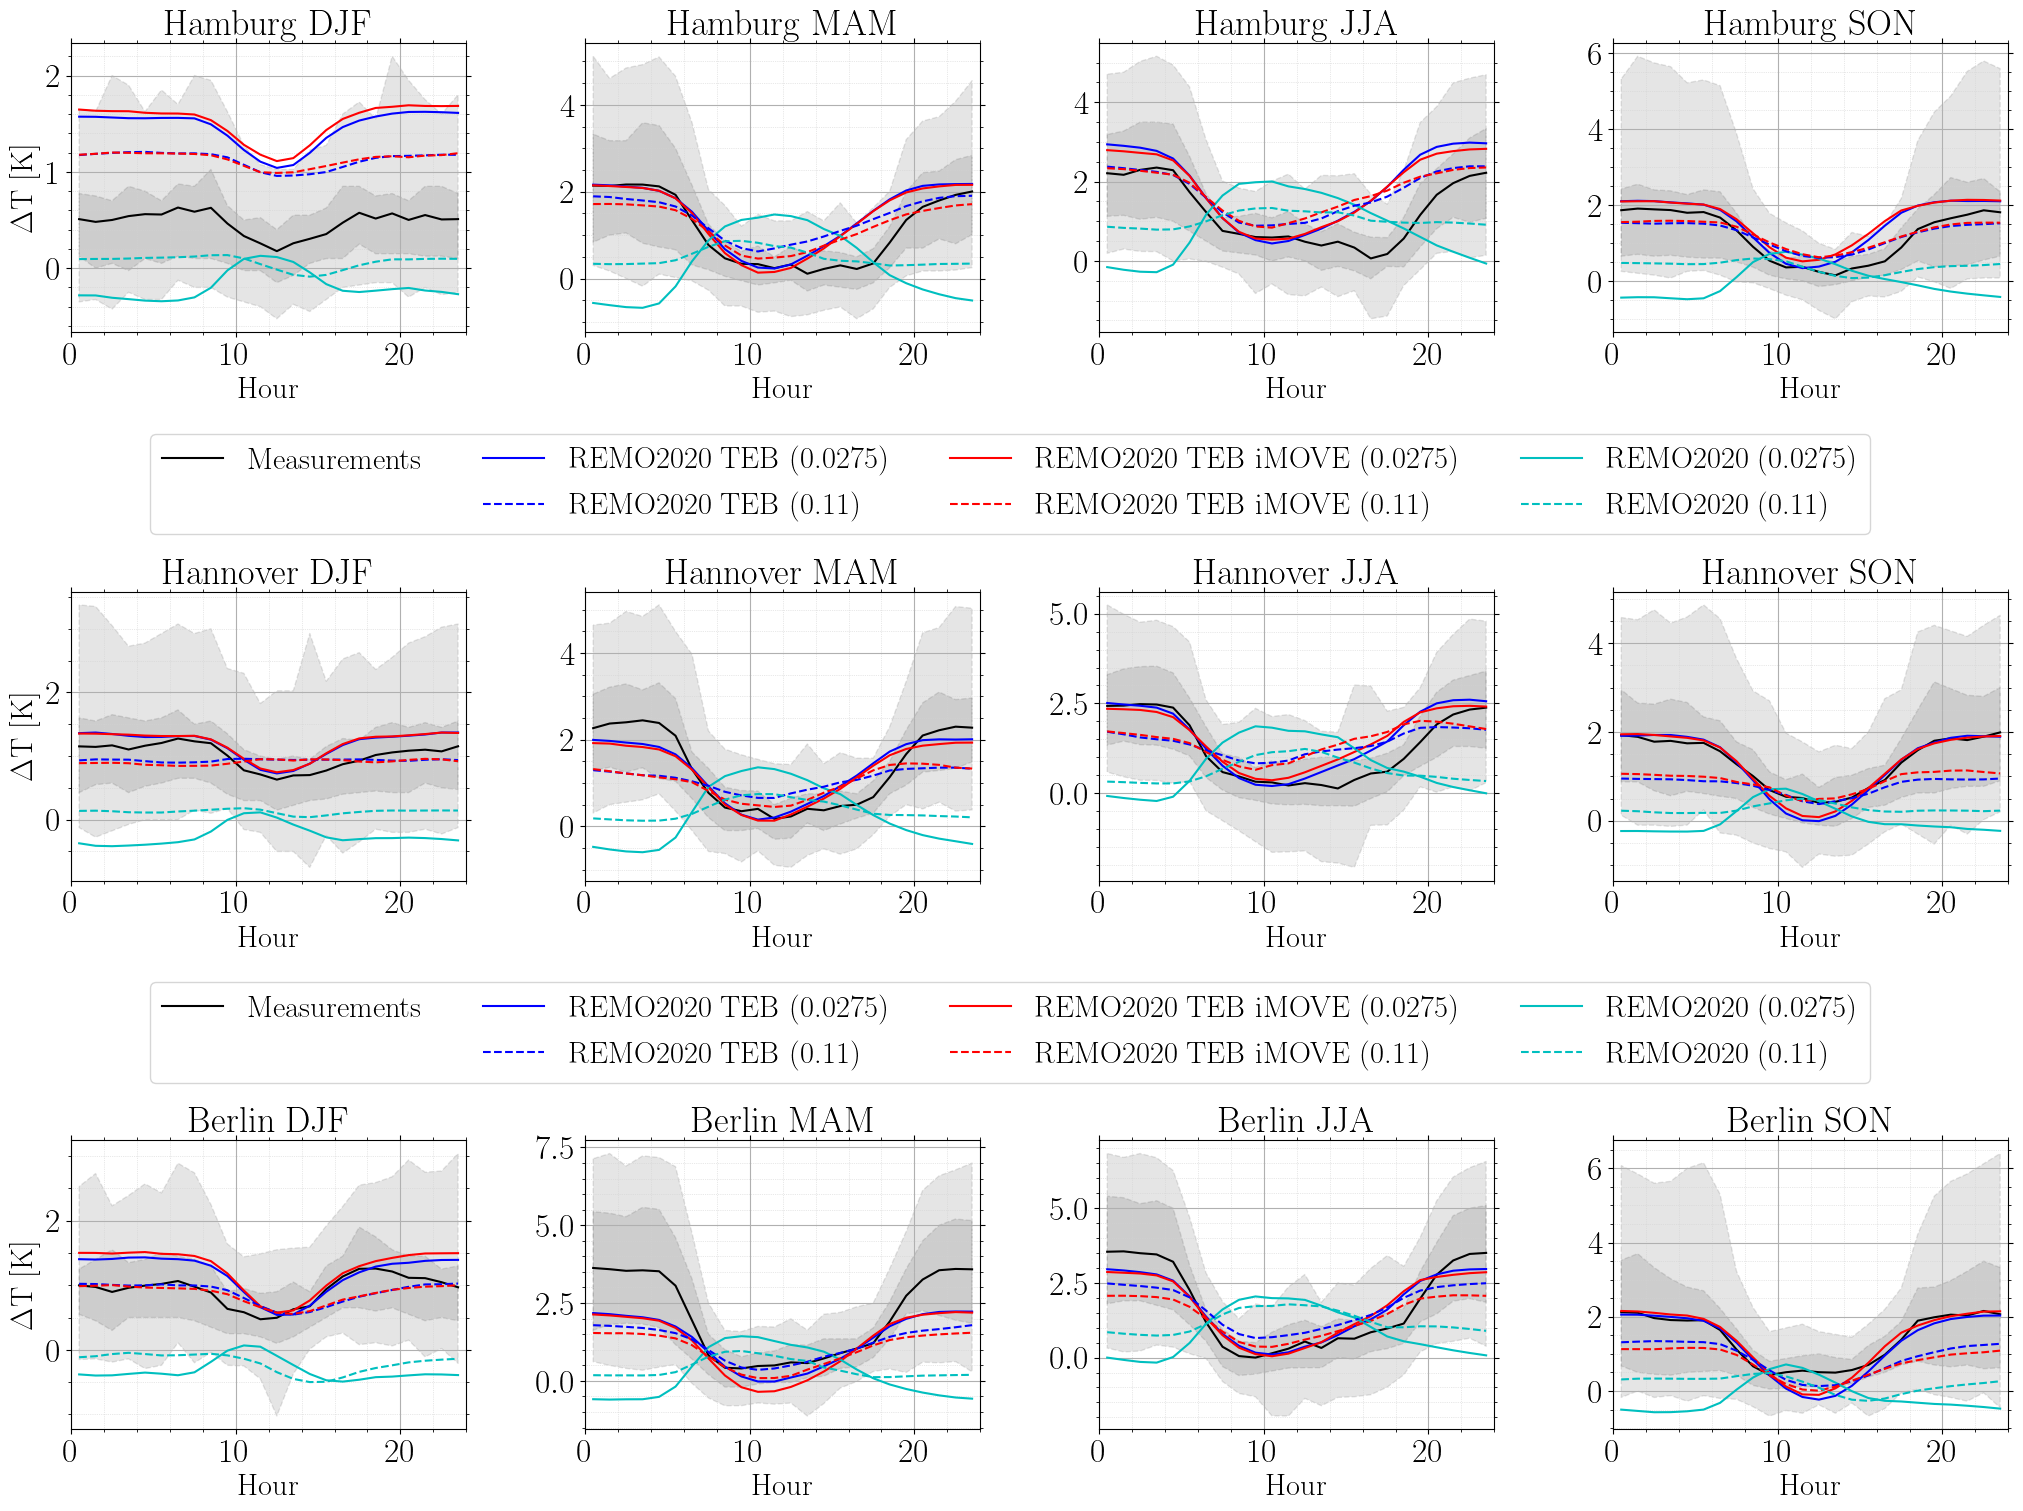

In [15]:
# plot specific configs
plt.rcParams["figure.subplot.hspace"] = 0.9
# Create subplots: station_count rows, 4 columns
fig, ax = plt.subplots(len(dwd_data), 4, figsize=(25, 18))
ax = ax.flatten()  # Flatten for easy indexing

# number of legend columns
ncol = 4
# some helper indexes
ind = 0
for seas in seasons:
    istat = 0
    for stat in dwd_data:
        ax[ind+istat].grid() # make grid and modify it
        ax[ind+istat].grid(which='minor', color='lightgrey', linestyle=':', linewidth=0.5)
        ax[ind+istat].minorticks_on() # use minor ticks
        # Urban plot (measurements)
        ax[ind+istat].plot(stat.data.hour.values+0.5,
                     stat.data.sel(season=seas).sel(quantile=0.5).values,
                     'k-', label="Measurements")
        for qq in ploquan:
            ax[ind+istat].fill_between(stat.data.hour.values+0.5,
                                stat.data.sel(season=seas).sel(quantile=qq).values, stat.data.sel(season=seas).sel(quantile=1.0-qq).values,
                                color='k', alpha=0.1, linewidth=1, linestyle = '--')
    
        for obj in modelruns:
            ax[ind+istat].plot(obj.vardata.hour.values+0.5,
                         obj.vardata[stat.station].sel(season=seas).sel(quantile=0.5).values,
                         obj.plstyle, label=obj.runame+" ("+obj.reso+")")

        ax[ind+istat].set_title(f"{stat.station} {seas}")
        ax[ind+istat].set_xlabel("Hour")
        ax[ind+istat].set_xlim([0,24])
        if seas == "DJF":
            ax[ind+istat].set_ylabel("$\Delta$T [K]")
            if(istat != (len(dwd_data)-1)*len(seasons)):
                # flip and insert one empty string
                handles, labels = ax[ind+istat].get_legend_handles_labels()
                empty_patch = mpatches.Patch(color='none', label='') # create a patch with no color
                handles.insert(ncol, empty_patch)
                labels.insert(ncol,'')
                ax[ind+istat].legend(flip(handles, ncol), flip(labels, ncol),loc=(0.2, -0.7), ncol=ncol, frameon=True)
        # increas counter
        istat += len(seasons)
    # increas counter
    ind += 1

    
plt.savefig(figpath + 'fig9.png', format="png", bbox_inches='tight', pad_inches=0)
plt.show()